# LipMatch AI: Ekstraksi Warna Kulit, Rekomendasi Shade, dan Virtual Try-On

Notebook ini diselaraskan dengan implementasi aktual pada `app.py` Streamlit LipMatch AI.

**Alur yang digunakan:**
1. Memuat foto wajah dan katalog lipstik `dataset.csv`.
2. Mendeteksi landmark wajah menggunakan MediaPipe Face Landmarker.
3. Mengambil median warna dari pipi kiri, pipi kanan, dan dahi.
4. Mengubah warna median ke RGB, HEX, dan CIELAB.
5. Mengelompokkan skin depth berdasarkan nilai L*: `Fair & Light`, `Medium & Tan`, atau `Deep`.
6. Mencocokkan 226 varian pada katalog ke palet referensi `Warm`, `Cool`, dan `Neutral` menggunakan cosine similarity pada fitur warna HSV.
7. Menampilkan tiga rekomendasi per kelompok dan simulasi warna lipstik pada area bibir.

**Catatan:** `Warm`, `Cool`, dan `Neutral` adalah kelompok palet rekomendasi. Sistem ini tidak mendiagnosis undertone pribadi. Hasil warna juga dipengaruhi pencahayaan, kamera, makeup, dan layar.

## 1. Instalasi dependensi

Jalankan cell ini sekali pada environment baru. Setelah instalasi, jika kernel meminta restart, restart kernel lalu lanjutkan dari cell import.

In [1]:
%pip install "mediapipe==0.10.35" "opencv-python-headless>=4.10,<5" "numpy>=1.26,<2.2" "pandas>=2.1,<3.0" "Pillow>=10.0" "scikit-image>=0.22" "matplotlib>=3.8"

## 2. Import library dan pengaturan utama

Indeks landmark dan palet referensi di bawah mengikuti `app.py`. HEX palet adalah anchor warna representatif yang dipakai aplikasi untuk mengoperasionalkan deskripsi warna, bukan kode resmi produk.

In [2]:
from __future__ import annotations

import colorsys
import io
import shutil
import tempfile
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
from PIL import Image, ImageColor, ImageOps
from skimage.color import rgb2lab
from IPython.display import display

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False

# Path dan URL mengikuti aplikasi Streamlit.
BASE_DIR = Path.cwd()
MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/face_landmarker.task"
)

# Titik sampel warna kulit dan lebar wajah.
SKIN_SAMPLE_INDICES = {
    "Pipi kiri": 205,
    "Pipi kanan": 425,
    "Dahi": 151,
}
FACE_LEFT_INDEX = 234
FACE_RIGHT_INDEX = 454

# Palet referensi per kelompok skin depth, sama dengan app.py.
REFERENCE_PALETTES = {
    "Fair & Light": {
        "Warm": {
            "description": "Nude peach, coral hangat, dan merah lembut.",
            "hexes": ["#DFA58F", "#E76F61", "#C9574A"],
        },
        "Cool": {
            "description": "Pink lembut, rosy nude, dan warna berry.",
            "hexes": ["#E7A1B0", "#C88791", "#8D2F52"],
        },
        "Neutral": {
            "description": "Mauve pink, merah klasik, dan plum muda.",
            "hexes": ["#B97D91", "#C83E4D", "#A86B91"],
        },
    },
    "Medium & Tan": {
        "Warm": {
            "description": "Merah bata hangat, terracotta, dan pink bernuansa keemasan.",
            "hexes": ["#A84532", "#B85C45", "#C8787D"],
        },
        "Cool": {
            "description": "Berry pekat, merah cranberry, dan mauve bernuansa dingin.",
            "hexes": ["#7E294D", "#9E2948", "#94627D"],
        },
        "Neutral": {
            "description": "Rose yang kaya, cokelat netral, dan merah seimbang.",
            "hexes": ["#A64D64", "#875A4C", "#B83C43"],
        },
    },
    "Deep": {
        "Warm": {
            "description": "Cokelat, burnt orange, dan deep coral.",
            "hexes": ["#5B3328", "#B84D2B", "#B84643"],
        },
        "Cool": {
            "description": "Plum, deep wine, dan merah berbasis biru.",
            "hexes": ["#642448", "#581E35", "#8C1836"],
        },
        "Neutral": {
            "description": "Merah bold, mocha pekat, dan berry gelap.",
            "hexes": ["#A51D32", "#644236", "#632343"],
        },
    },
}

def hex_to_rgb(hex_value: str) -> tuple[int, int, int]:
    """Mengubah HEX valid seperti #A63E59 menjadi tuple RGB."""
    return tuple(ImageColor.getcolor(str(hex_value).strip(), "RGB"))

def rgb_to_lab(rgb: tuple[float, float, float] | np.ndarray) -> np.ndarray:
    """Mengubah RGB 0-255 menjadi CIELAB."""
    rgb_array = np.asarray(rgb, dtype=np.float32)
    return rgb2lab((rgb_array / 255.0).reshape(1, 1, 3))[0, 0]

def estimate_skin_depth(lab: np.ndarray) -> str:
    """Aturan skin-depth yang sama dengan app.py, berdasarkan nilai L*."""
    lightness = float(lab[0])
    if lightness >= 65:
        return "Fair & Light"
    if lightness >= 45:
        return "Medium & Tan"
    return "Deep"

def color_feature_vector(rgb: tuple[int, int, int] | np.ndarray) -> np.ndarray:
    """
    Fitur warna HSV melingkar.
    Hue direpresentasikan dengan sin/cos agar hue dekat 0 dan 360 derajat
    tidak dianggap berjauhan.
    """
    values = np.asarray(rgb, dtype=np.float64) / 255.0
    red, green, blue = values.tolist()
    hue, saturation, value = colorsys.rgb_to_hsv(red, green, blue)
    angle = 2.0 * np.pi * hue
    return np.asarray(
        [
            saturation * np.cos(angle),
            saturation * np.sin(angle),
            saturation,
            value,
        ],
        dtype=np.float64,
    )

def cosine_similarity_vectors(vector_a: np.ndarray, vector_b: np.ndarray) -> float:
    """Cosine similarity untuk dua vektor fitur warna."""
    a = np.asarray(vector_a, dtype=np.float64)
    b = np.asarray(vector_b, dtype=np.float64)
    denominator = float(np.linalg.norm(a) * np.linalg.norm(b))
    if denominator == 0:
        return 0.0
    return float(np.dot(a, b) / denominator)

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("Mode:", "Google Colab" if IN_COLAB else "Jupyter lokal")

OpenCV: 4.14.0
MediaPipe: 0.10.35
Mode: Google Colab


## 3. Memuat katalog lipstik

Notebook memakai `dataset.csv` yang sama dengan Streamlit, dengan kolom `Nama Produk`, `Varian Warna`, `Hex Code`, `Harga`, `Deskripsi`, dan `Link Produk`.

Jika file tidak berada di folder kerja, Colab akan meminta upload. Di Jupyter lokal, masukkan path file CSV.

In [3]:
DATASET_PATH = Path("dataset.csv")

if not DATASET_PATH.exists():
    if IN_COLAB:
        print("Upload file dataset.csv yang digunakan oleh aplikasi Streamlit.")
        uploaded_dataset = files.upload()
        csv_files = [name for name in uploaded_dataset if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Tidak ada file CSV yang diunggah.")
        DATASET_PATH = Path(csv_files[0])
    else:
        entered_path = input("Path dataset.csv (contoh: ./dataset.csv): ").strip()
        if entered_path:
            DATASET_PATH = Path(entered_path)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATASET_PATH}. "
        "Letakkan dataset.csv di folder notebook atau perbarui DATASET_PATH."
    )

catalog = pd.read_csv(DATASET_PATH)
required_columns = [
    "Nama Produk",
    "Varian Warna",
    "Hex Code",
    "Harga",
    "Deskripsi",
    "Link Produk",
]
missing_columns = [col for col in required_columns if col not in catalog.columns]
if missing_columns:
    raise ValueError("Kolom dataset tidak lengkap: " + ", ".join(missing_columns))

catalog = catalog.dropna(subset=required_columns).copy()
catalog["Hex Code"] = catalog["Hex Code"].astype(str).str.strip()
catalog["_RGB"] = catalog["Hex Code"].apply(hex_to_rgb)

print(f"Dataset berhasil dimuat: {len(catalog)} varian lipstik")
display(catalog[required_columns].head())

Upload file dataset.csv yang digunakan oleh aplikasi Streamlit.


Saving dataset.csv to dataset.csv
Dataset berhasil dimuat: 226 varian lipstik


,Nama Produk,Varian Warna,Hex Code,Harga,Deskripsi,Link Produk
0,Wardah Colorfit Ultralight Matte Lipstick Kore...,09 Romantic Namsan,#A63E59,Rp49.900,"Lipstik berwarna Mauve pink, nude pink dengan ...",https://www.wardahbeauty.com/id/product/make-u...
1,Wardah Colorfit Ultralight Matte Lipstick Kore...,10 Stunning Seoul,#B33E2C,Rp49.900,Lipstik berwarna Merah dengan undertone oranye...,https://www.wardahbeauty.com/id/product/make-u...
2,Wardah Colorfit Ultralight Matte Lipstick Kore...,11 Sunkissed Jeju,#A23B4A,Rp49.900,Lipstik berwarna Cokelat medium dengan sentuha...,https://www.wardahbeauty.com/id/product/make-u...
3,Wardah Colorfit Ultralight Matte Lipstick Kore...,12 Autumn Nami,#9C3027,Rp49.900,Lipstik berwarna Merah bata atau terracotta de...,https://www.wardahbeauty.com/id/product/make-u...
4,Wardah Colorfit Ultralight Matte Lipstick Kore...,13 Upbeat Hongdae,#A51D3D,Rp49.900,Lipstik berwarna Merah berry dengan undertone ...,https://www.wardahbeauty.com/id/product/make-u...


## 4. Memuat foto wajah

Gunakan foto frontal dengan pencahayaan merata. Hindari filter, mode beauty, makeup tebal pada area sampel, serta rambut atau benda yang menutupi dahi dan pipi.

Upload satu foto wajah (JPG, JPEG, PNG, atau WEBP).


Saving 19bfbe145991fdd7c326ac8acf1f947b.jpg to 19bfbe145991fdd7c326ac8acf1f947b.jpg
Foto: 19bfbe145991fdd7c326ac8acf1f947b.jpg
Ukuran gambar (tinggi, lebar, kanal): (895, 637, 3)


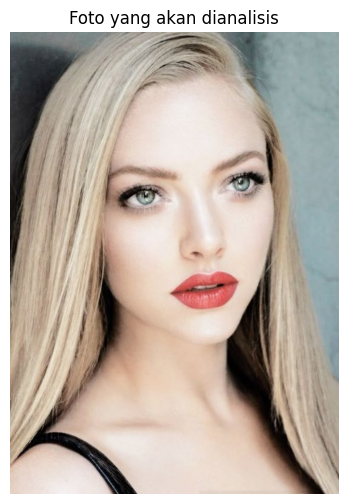

In [4]:
if IN_COLAB:
    print("Upload satu foto wajah (JPG, JPEG, PNG, atau WEBP).")
    uploaded_images = files.upload()
    image_candidates = [
        name for name in uploaded_images
        if Path(name).suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    ]
    if not image_candidates:
        raise FileNotFoundError("Tidak ada file gambar yang sesuai diunggah.")
    IMAGE_NAME = image_candidates[0]
    image_bytes = uploaded_images[IMAGE_NAME]
else:
    IMAGE_PATH = Path("foto_wajah.jpg")
    if not IMAGE_PATH.exists():
        entered_image_path = input(
            "Path foto wajah (contoh: ./foto_wajah.jpg): "
        ).strip()
        if entered_image_path:
            IMAGE_PATH = Path(entered_image_path)
    if not IMAGE_PATH.exists():
        raise FileNotFoundError(
            f"Foto tidak ditemukan: {IMAGE_PATH}. Perbarui IMAGE_PATH."
        )
    IMAGE_NAME = IMAGE_PATH.name
    image_bytes = IMAGE_PATH.read_bytes()

def decode_uploaded_image(image_bytes: bytes, max_side: int = 1600) -> np.ndarray:
    """Decode foto ke RGB dan resize maksimum 1600 px, sama dengan app.py."""
    image = Image.open(io.BytesIO(image_bytes))
    image = ImageOps.exif_transpose(image).convert("RGB")
    width, height = image.size
    longest = max(width, height)
    if longest > max_side:
        scale = max_side / float(longest)
        image = image.resize(
            (max(1, int(width * scale)), max(1, int(height * scale))),
            Image.Resampling.LANCZOS,
        )
    return np.asarray(image, dtype=np.uint8)

image_rgb = decode_uploaded_image(image_bytes)
print("Foto:", IMAGE_NAME)
print("Ukuran gambar (tinggi, lebar, kanal):", image_rgb.shape)
plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title("Foto yang akan dianalisis")
plt.axis("off")
plt.show()

## 5. Deteksi wajah dan ekstraksi warna kulit

MediaPipe Face Landmarker mendeteksi landmark wajah. Notebook kemudian mengambil piksel dalam lingkaran kecil pada pipi kiri, pipi kanan, dan dahi. Radius sampel adalah 3,5% dari lebar wajah, sama seperti aplikasi.

In [5]:
def ensure_face_model() -> str:
    """Gunakan model lokal jika ada; jika tidak, unduh model resmi satu kali."""
    local_model = BASE_DIR / "models" / "face_landmarker.task"
    if local_model.exists() and local_model.stat().st_size > 100_000:
        return str(local_model)

    cached_model = Path(tempfile.gettempdir()) / "lipmatch_face_landmarker.task"
    if cached_model.exists() and cached_model.stat().st_size > 100_000:
        return str(cached_model)

    temp_download = cached_model.with_suffix(".download")
    try:
        request = urllib.request.Request(
            MODEL_URL, headers={"User-Agent": "LipMatchAI/1.0"}
        )
        with urllib.request.urlopen(request, timeout=120) as response, open(
            temp_download, "wb"
        ) as output:
            shutil.copyfileobj(response, output)

        if not temp_download.exists() or temp_download.stat().st_size < 100_000:
            raise RuntimeError("File model terlalu kecil atau unduhan tidak lengkap.")

        temp_download.replace(cached_model)
        return str(cached_model)
    except Exception as exc:
        if temp_download.exists():
            temp_download.unlink(missing_ok=True)
        raise RuntimeError(
            "Model Face Landmarker belum tersedia. Periksa koneksi internet "
            "pada penggunaan pertama. Detail teknis: " + str(exc)
        ) from exc

def landmark_pixel(landmarks: list, index: int, image_shape: tuple[int, ...]) -> np.ndarray:
    height, width = image_shape[:2]
    point = landmarks[index]
    x = int(np.clip(round(float(point.x) * width), 0, width - 1))
    y = int(np.clip(round(float(point.y) * height), 0, height - 1))
    return np.array([x, y], dtype=np.int32)

def analyze_skin_color(image_rgb: np.ndarray) -> dict:
    model_path = ensure_face_model()
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(image_rgb),
    )
    options = mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=model_path),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_faces=1,
        min_face_detection_confidence=0.5,
    )

    with mp.tasks.vision.FaceLandmarker.create_from_options(options) as landmarker:
        result = landmarker.detect(mp_image)

    if not result.face_landmarks:
        raise ValueError(
            "Wajah belum terdeteksi. Gunakan foto frontal dengan pencahayaan cukup "
            "dan wajah tidak tertutup rambut atau benda lain."
        )

    landmarks = result.face_landmarks[0]
    if len(landmarks) <= FACE_RIGHT_INDEX:
        raise ValueError("Titik wajah tidak lengkap. Coba foto lain.")

    # Koordinat normalisasi seluruh landmark disimpan untuk virtual try-on.
    landmarks_xy = np.asarray(
        [[float(point.x), float(point.y)] for point in landmarks],
        dtype=np.float32,
    )

    height, width = image_rgb.shape[:2]
    centers = {
        name: landmark_pixel(landmarks, index, image_rgb.shape)
        for name, index in SKIN_SAMPLE_INDICES.items()
    }
    face_width = float(
        np.linalg.norm(
            landmark_pixel(landmarks, FACE_LEFT_INDEX, image_rgb.shape)
            - landmark_pixel(landmarks, FACE_RIGHT_INDEX, image_rgb.shape)
        )
    )
    radius = max(3, int(face_width * 0.035))
    yy, xx = np.ogrid[:height, :width]
    sampled_regions = []
    region_rgb = {}

    for name, center in centers.items():
        cx, cy = int(center[0]), int(center[1])
        mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= radius**2
        pixels = image_rgb[mask]
        if pixels.size == 0:
            raise ValueError(f"Sampel warna {name.lower()} tidak berhasil diambil.")
        region_rgb[name] = np.median(pixels, axis=0)
        sampled_regions.append(pixels)

    all_pixels = np.concatenate(sampled_regions, axis=0)
    median_rgb = np.median(all_pixels, axis=0)
    median_rgb_int = np.clip(np.rint(median_rgb), 0, 255).astype(np.uint8)
    skin_hex = "#{:02X}{:02X}{:02X}".format(*median_rgb_int)
    lab = rgb_to_lab(median_rgb)
    skin_depth = estimate_skin_depth(lab)

    sample_preview = image_rgb.copy()
    for center in centers.values():
        cv2.circle(
            sample_preview,
            tuple(map(int, center)),
            radius,
            (40, 220, 90),
            max(2, int(max(height, width) / 500)),
        )

    return {
        "skin_rgb": tuple(int(value) for value in median_rgb_int),
        "skin_hex": skin_hex,
        "lab": tuple(float(value) for value in lab),
        "skin_depth": skin_depth,
        "sample_preview": sample_preview,
        "landmarks_xy": landmarks_xy,
        "region_rgb": {
            key: tuple(float(v) for v in value)
            for key, value in region_rgb.items()
        },
    }

analysis = analyze_skin_color(image_rgb)
print("Analisis warna kulit selesai.")

Analisis warna kulit selesai.


## 6. Melihat hasil ekstraksi warna kulit

Kategori skin depth mengikuti aturan pada `app.py`: `L* ≥ 65` menjadi `Fair & Light`, `45 ≤ L* < 65` menjadi `Medium & Tan`, dan `L* < 45` menjadi `Deep`.

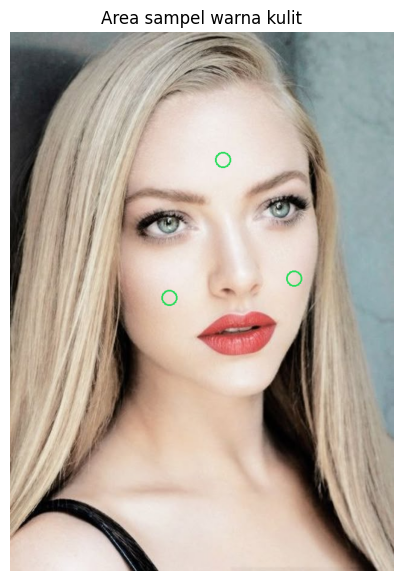

Nama file: 19bfbe145991fdd7c326ac8acf1f947b.jpg
RGB median: (240, 222, 214)
HEX: #F0DED6
CIELAB (L*, a*, b*): (89.68, 4.84, 6.15)
Kelompok skin depth: Fair & Light

Median RGB tiap area sampel:


,Area,R,G,B
0,Pipi kiri,239.0,220.0,211.0
1,Pipi kanan,237.0,219.0,208.0
2,Dahi,243.0,235.0,232.0


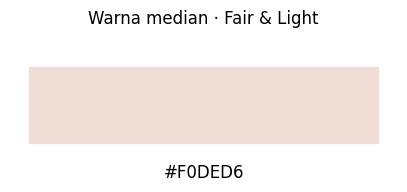

In [6]:
plt.figure(figsize=(7, 7))
plt.imshow(analysis["sample_preview"])
plt.title("Area sampel warna kulit")
plt.axis("off")
plt.show()

lab = analysis["lab"]
print("Nama file:", IMAGE_NAME)
print("RGB median:", analysis["skin_rgb"])
print("HEX:", analysis["skin_hex"])
print(f"CIELAB (L*, a*, b*): ({lab[0]:.2f}, {lab[1]:.2f}, {lab[2]:.2f})")
print("Kelompok skin depth:", analysis["skin_depth"])

print("\nMedian RGB tiap area sampel:")
region_table = pd.DataFrame(
    [
        {"Area": area, "R": round(rgb[0], 1), "G": round(rgb[1], 1), "B": round(rgb[2], 1)}
        for area, rgb in analysis["region_rgb"].items()
    ]
)
display(region_table)

fig, ax = plt.subplots(figsize=(5, 1.8))
ax.add_patch(plt.Rectangle((0.05, 0.2), 0.9, 0.55, color=analysis["skin_hex"]))
ax.text(0.5, 0.05, analysis["skin_hex"], ha="center", va="top", fontsize=12)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title(f"Warna median · {analysis['skin_depth']}")
plt.show()

## 7. Fungsi rekomendasi shade

Logika ini mengikuti `recommend_shades()` di Streamlit:
- Mengubah warna HEX produk menjadi fitur HSV melingkar.
- Membandingkan setiap produk dengan tiga anchor HEX di setiap palet `Warm`, `Cool`, dan `Neutral` untuk skin depth yang terdeteksi.
- Menggunakan skor tertinggi terhadap anchor dalam setiap palet.
- Menetapkan setiap produk ke satu palet dengan skor tertinggi agar rekomendasi antargrup tidak berulang.
- Mengambil tiga shade teratas pada masing-masing kelompok.

In [7]:
def recommend_shades(catalog: pd.DataFrame, skin_depth: str) -> dict[str, pd.DataFrame]:
    """
    Mencocokkan warna produk ke palet referensi untuk skin depth terdeteksi.
    Warm/Cool/Neutral merupakan kelompok palet rekomendasi, bukan diagnosis
    undertone pengguna.
    """
    if skin_depth not in REFERENCE_PALETTES:
        skin_depth = "Medium & Tan"

    ranked = catalog.copy()
    product_vectors = {
        index: color_feature_vector(rgb)
        for index, rgb in ranked["_RGB"].items()
    }

    score_columns = {}
    for palette_name, palette_info in REFERENCE_PALETTES[skin_depth].items():
        reference_vectors = [
            color_feature_vector(hex_to_rgb(hex_value))
            for hex_value in palette_info["hexes"]
        ]
        score_columns[palette_name] = pd.Series(
            {
                index: max(
                    cosine_similarity_vectors(product_vector, reference_vector)
                    for reference_vector in reference_vectors
                )
                for index, product_vector in product_vectors.items()
            },
            dtype=float,
        )

    score_frame = pd.DataFrame(score_columns, index=ranked.index)

    # Tiap produk hanya masuk ke kelompok palet dengan skor tertinggi.
    ranked["_KategoriReferensi"] = score_frame.idxmax(axis=1)

    recommendations = {}
    for palette_name in ["Warm", "Cool", "Neutral"]:
        subset = ranked[ranked["_KategoriReferensi"] == palette_name].copy()
        subset["_Cosine"] = score_frame.loc[subset.index, palette_name]
        subset = subset.sort_values(
            ["_Cosine", "Nama Produk", "Varian Warna"],
            ascending=[False, True, True],
        )
        recommendations[palette_name] = subset.head(3).copy()

    return recommendations

recommendations = recommend_shades(catalog, analysis["skin_depth"])

for category in ["Warm", "Cool", "Neutral"]:
    print(f"\n{category} | {REFERENCE_PALETTES[analysis['skin_depth']][category]['description']}")
    rows = recommendations[category]
    if rows.empty:
        print("Belum ada shade pada kelompok ini.")
        continue
    display(
        rows[
            [
                "Nama Produk",
                "Varian Warna",
                "Hex Code",
                "Harga",
                "Deskripsi",
                "Link Produk",
                "_Cosine",
            ]
        ].rename(columns={"_Cosine": "Cosine similarity"})
    )

print(
    "\nCatatan: skor cosine similarity adalah ukuran kemiripan terhadap palet referensi, "
    "bukan probabilitas atau jaminan bahwa shade pasti cocok."
)


Warm | Nude peach, coral hangat, dan merah lembut.


,Nama Produk,Varian Warna,Hex Code,Harga,Deskripsi,Link Produk,Cosine similarity
12,Wardah Colorfit Ultralight Matte Lipstick,08 Woodsy Brown,#98574F,Rp43.000,Lipstik berwarna Cokelat gelap dengan nuansa m...,https://www.wardahbeauty.com/id/product/make-u...,0.999989
125,MAKE OVER Creamy Lust Lipstick,12 Nude in Paradise,#C99D88,Rp83.000,Lipstik berwarna peach nude dengan nuansa nude...,https://www.makeoverforall.com/product/make-ov...,0.999840
104,SOMETHINC Forever Stay Comfort Lip Glaze,12 Honest,#D9A08A,Rp89.100,Lipstik berwarna nude peach dengan nuansa peac...,https://www.somethinc.com/en/product/detail/fo...,0.999830



Cool | Pink lembut, rosy nude, dan warna berry.


,Nama Produk,Varian Warna,Hex Code,Harga,Deskripsi,Link Produk,Cosine similarity
97,SOMETHINC Forever Stay Comfort Lip Glaze,05 Unreal,#C98591,Rp89.100,Lipstik berwarna nude pink dengan nuansa merah...,https://www.somethinc.com/en/product/detail/fo...,0.999844
114,MAKE OVER Creamy Lust Lipstick,01 Sassy Pink,#D88C9C,Rp83.000,Lipstik berwarna soft rosy pink dengan nuansa ...,https://www.makeoverforall.com/product/make-ov...,0.999774
179,BLP Beauty Lip Coat,Peppermint Pink,#D58A9B,Rp119.200,Lipstik berwarna soft pink dengan nuansa merah...,https://blpbeauty.com/id/collections/onthelips...,0.999596



Neutral | Mauve pink, merah klasik, dan plum muda.


,Nama Produk,Varian Warna,Hex Code,Harga,Deskripsi,Link Produk,Cosine similarity
137,Implora Lipstick Intense Matte,09 Red Summer,#E52D3D,Rp25.000,Lipstik berwarna bright red dengan nuansa mera...,https://implora.co.id/implora-lipstick-intense...,0.999887
147,Implora Cheek and Lip Tint,03 Candy Apple,#D93242,Rp24.000,Lipstik berwarna apple red dengan nuansa merah...,https://implora.co.id/implora-cheek-and-lip-tint,0.999882
215,BLP Beauty Lip Petals,River,#B77B91,Rp89.400,Lipstik berwarna soft pink mauve dengan nuansa...,https://blpbeauty.com/id/collections/onthelips...,0.999863



Catatan: skor cosine similarity adalah ukuran kemiripan terhadap palet referensi, bukan probabilitas atau jaminan bahwa shade pasti cocok.


## 8. Fungsi virtual try-on

Bagian ini menggunakan landmark bibir yang sama dengan Streamlit. Warna diterapkan hanya pada area bibir, dengan bagian dalam mulut dikecualikan. Pencampuran dilakukan pada kanal warna CIELAB agar variasi pencahayaan asli tetap lebih terjaga.

In [8]:
# Indeks kontur bibir, sama dengan app.py.
LIP_OUTER_INDICES = [
    61, 185, 40, 39, 37, 0, 267, 269, 270, 409,
    291, 375, 321, 405, 314, 17, 84, 181, 91, 146,
]
LIP_INNER_INDICES = [
    78, 191, 80, 81, 82, 13, 312, 311, 310, 415,
    308, 324, 318, 402, 317, 14, 87, 178, 88, 95,
]

def lip_landmark_pixel(
    landmarks_xy: np.ndarray,
    index: int,
    image_shape: tuple[int, ...],
) -> np.ndarray:
    height, width = image_shape[:2]
    x = int(np.clip(round(float(landmarks_xy[index, 0]) * width), 0, width - 1))
    y = int(np.clip(round(float(landmarks_xy[index, 1]) * height), 0, height - 1))
    return np.array([x, y], dtype=np.int32)

def lip_points_from_indices(indices, landmarks_xy, image_shape) -> np.ndarray:
    return np.asarray(
        [lip_landmark_pixel(landmarks_xy, index, image_shape) for index in indices],
        dtype=np.int32,
    )

def create_lip_mask(
    landmarks_xy: np.ndarray,
    image_shape: tuple[int, ...],
    feather_kernel: int = 7,
):
    """Membuat mask bibir dan mengecualikan bagian dalam mulut."""
    height, width = image_shape[:2]
    if len(landmarks_xy) <= max(LIP_OUTER_INDICES + LIP_INNER_INDICES):
        raise ValueError("Landmark bibir tidak lengkap. Coba foto lain.")

    outer_mask = np.zeros((height, width), dtype=np.uint8)
    inner_mask = np.zeros((height, width), dtype=np.uint8)

    outer_points = lip_points_from_indices(LIP_OUTER_INDICES, landmarks_xy, image_shape)
    inner_points = lip_points_from_indices(LIP_INNER_INDICES, landmarks_xy, image_shape)

    cv2.fillPoly(outer_mask, [outer_points], 255)
    cv2.fillPoly(inner_mask, [inner_points], 255)
    hard_mask = cv2.subtract(outer_mask, inner_mask)

    kernel = max(1, int(feather_kernel))
    if kernel % 2 == 0:
        kernel += 1

    if kernel > 1:
        soft_alpha = (
            cv2.GaussianBlur(hard_mask, (kernel, kernel), 0).astype(np.float32) / 255.0
        )
    else:
        soft_alpha = hard_mask.astype(np.float32) / 255.0

    soft_alpha[hard_mask == 0] = 0.0
    return hard_mask, soft_alpha

def apply_lipstick_color(
    image_rgb: np.ndarray,
    landmarks_xy: np.ndarray,
    hex_color: str,
    strength: float = 0.62,
):
    """Menerapkan warna shade pada bibir tanpa mewarnai seluruh wajah."""
    if not 0.0 <= strength <= 1.0:
        raise ValueError("Intensitas warna harus antara 0 dan 1.")

    source = np.asarray(image_rgb, dtype=np.uint8)
    hard_mask, soft_alpha = create_lip_mask(landmarks_xy, source.shape)

    if np.count_nonzero(hard_mask) < 30:
        raise ValueError(
            "Area bibir tidak berhasil dideteksi. Coba foto yang lebih frontal dan jelas."
        )

    target_rgb = np.asarray(hex_to_rgb(hex_color), dtype=np.uint8).reshape(1, 1, 3)
    source_lab = cv2.cvtColor(source, cv2.COLOR_RGB2LAB).astype(np.float32)
    target_lab = cv2.cvtColor(target_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)[0, 0]

    recolored_lab = source_lab.copy()
    recolored_lab[:, :, 1] = (
        source_lab[:, :, 1] * (1.0 - strength) + target_lab[1] * strength
    )
    recolored_lab[:, :, 2] = (
        source_lab[:, :, 2] * (1.0 - strength) + target_lab[2] * strength
    )

    recolored_rgb = cv2.cvtColor(
        np.clip(recolored_lab, 0, 255).astype(np.uint8),
        cv2.COLOR_LAB2RGB,
    )

    alpha = soft_alpha[..., None]
    result = (
        source.astype(np.float32) * (1.0 - alpha)
        + recolored_rgb.astype(np.float32) * alpha
    )
    result_rgb = np.clip(result, 0, 255).astype(np.uint8)

    # Pertahankan seluruh piksel di luar mask seperti foto asli.
    result_rgb[hard_mask == 0] = source[hard_mask == 0]
    return result_rgb, hard_mask

## 9. Menampilkan sembilan virtual try-on

Ubah `try_on_strength` jika ingin warna lebih tipis atau lebih pekat. Nilai default `0.62` sama dengan nilai awal slider pada Streamlit.


Warm shades: Nude peach, coral hangat, dan merah lembut.


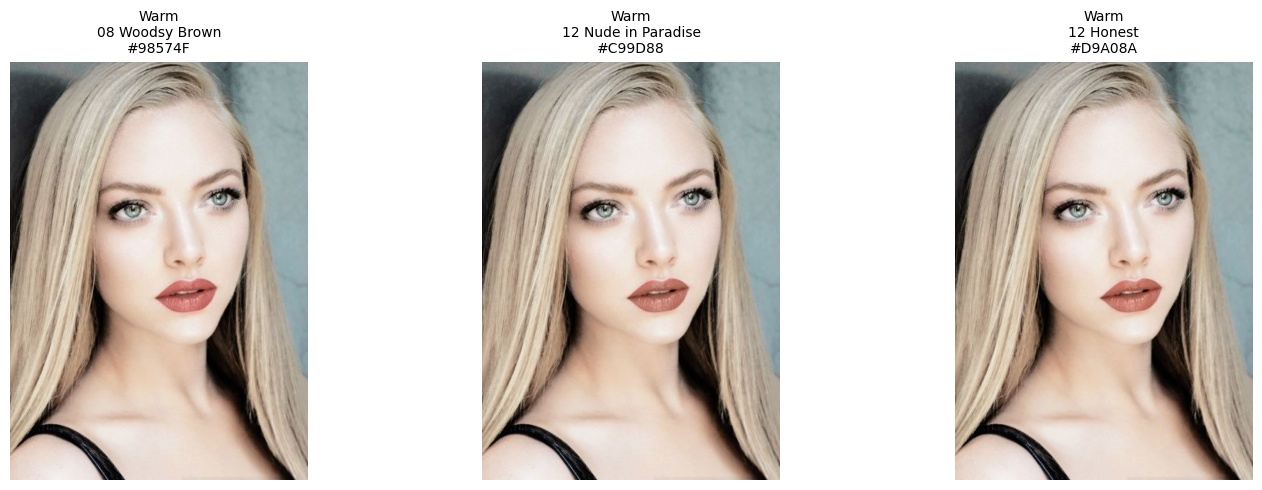


Cool shades: Pink lembut, rosy nude, dan warna berry.


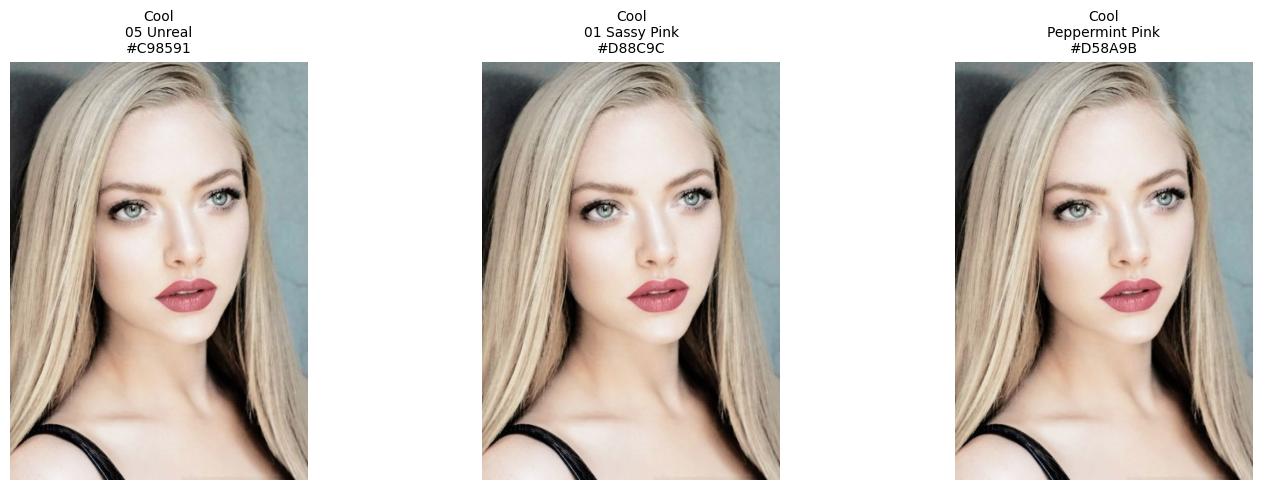


Neutral shades: Mauve pink, merah klasik, dan plum muda.


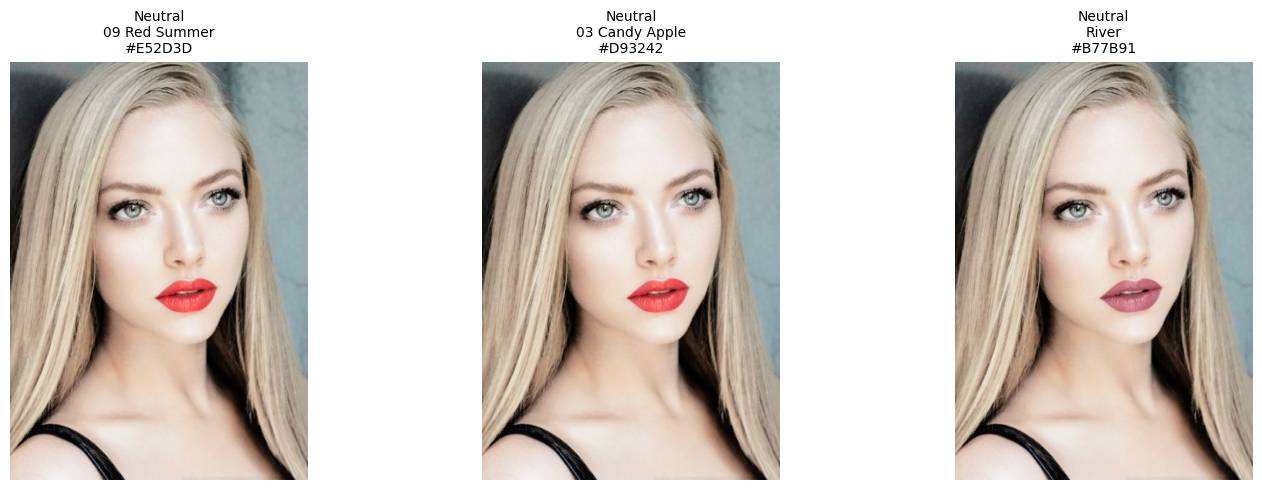

Jumlah preview yang dibuat: 9


In [9]:
try_on_strength = 0.62  # rentang 0.30-0.90 mengikuti slider Streamlit
virtual_try_on_images = {}
virtual_try_on_masks = {}

for category in ["Warm", "Cool", "Neutral"]:
    rows = recommendations[category]
    palette_description = REFERENCE_PALETTES[analysis["skin_depth"]][category]["description"]
    print(f"\n{category} shades: {palette_description}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= len(rows):
            ax.set_title("Shade belum tersedia")
            continue

        row = rows.iloc[i]
        preview, mask = apply_lipstick_color(
            image_rgb=image_rgb,
            landmarks_xy=analysis["landmarks_xy"],
            hex_color=str(row["Hex Code"]),
            strength=try_on_strength,
        )
        key = (category, str(row["Varian Warna"]))
        virtual_try_on_images[key] = preview
        virtual_try_on_masks[key] = mask

        ax.imshow(preview)
        ax.set_title(
            f"{category}\n{row['Varian Warna']}\n{row['Hex Code']}",
            fontsize=10,
        )

    plt.tight_layout()
    plt.show()

print(f"Jumlah preview yang dibuat: {len(virtual_try_on_images)}")

## 10. Ringkasan hasil dan ekspor

Tabel di bawah menggabungkan sembilan rekomendasi. Opsional, simpan tabel sebagai CSV dan hasil virtual try-on sebagai PNG untuk dokumentasi proyek.

In [10]:
recommendation_tables = []
for category in ["Warm", "Cool", "Neutral"]:
    rows = recommendations[category].copy()
    rows["Kategori Rekomendasi"] = category
    recommendation_tables.append(rows)

recommendations_all = pd.concat(recommendation_tables, ignore_index=True)
export_columns = [
    "Kategori Rekomendasi",
    "Nama Produk",
    "Varian Warna",
    "Hex Code",
    "Harga",
    "Deskripsi",
    "Link Produk",
    "_Cosine",
]
recommendations_export = recommendations_all[export_columns].rename(
    columns={"_Cosine": "Cosine similarity"}
)
display(recommendations_export)

# Simpan hasil numerik analisis warna.
skin_summary = pd.DataFrame([{
    "image_file": IMAGE_NAME,
    "skin_r": analysis["skin_rgb"][0],
    "skin_g": analysis["skin_rgb"][1],
    "skin_b": analysis["skin_rgb"][2],
    "skin_hex": analysis["skin_hex"],
    "lab_l": analysis["lab"][0],
    "lab_a": analysis["lab"][1],
    "lab_b": analysis["lab"][2],
    "skin_depth": analysis["skin_depth"],
}])

skin_summary.to_csv("lipmatch_skin_analysis.csv", index=False)
recommendations_export.to_csv("lipmatch_recommendations.csv", index=False)

# Simpan preview dan mask sebagai file PNG.
for (category, shade_name), preview in virtual_try_on_images.items():
    safe_name = "".join(
        char.lower() if char.isalnum() else "_"
        for char in f"{category}_{shade_name}"
    ).strip("_")
    Image.fromarray(preview).save(f"lipmatch_tryon_{safe_name}.png")

if virtual_try_on_masks:
    first_mask = next(iter(virtual_try_on_masks.values()))
    cv2.imwrite("lipmatch_lip_mask_debug.png", first_mask)

print("File tersimpan:")
print("- lipmatch_skin_analysis.csv")
print("- lipmatch_recommendations.csv")
print("- lipmatch_tryon_<kategori>_<shade>.png (setiap shade)")
print("- lipmatch_lip_mask_debug.png")

,Kategori Rekomendasi,Nama Produk,Varian Warna,Hex Code,Harga,Deskripsi,Link Produk,Cosine similarity
0,Warm,Wardah Colorfit Ultralight Matte Lipstick,08 Woodsy Brown,#98574F,Rp43.000,Lipstik berwarna Cokelat gelap dengan nuansa m...,https://www.wardahbeauty.com/id/product/make-u...,0.999989
1,Warm,MAKE OVER Creamy Lust Lipstick,12 Nude in Paradise,#C99D88,Rp83.000,Lipstik berwarna peach nude dengan nuansa nude...,https://www.makeoverforall.com/product/make-ov...,0.999840
2,Warm,SOMETHINC Forever Stay Comfort Lip Glaze,12 Honest,#D9A08A,Rp89.100,Lipstik berwarna nude peach dengan nuansa peac...,https://www.somethinc.com/en/product/detail/fo...,0.999830
3,Cool,SOMETHINC Forever Stay Comfort Lip Glaze,05 Unreal,#C98591,Rp89.100,Lipstik berwarna nude pink dengan nuansa merah...,https://www.somethinc.com/en/product/detail/fo...,0.999844
4,Cool,MAKE OVER Creamy Lust Lipstick,01 Sassy Pink,#D88C9C,Rp83.000,Lipstik berwarna soft rosy pink dengan nuansa ...,https://www.makeoverforall.com/product/make-ov...,0.999774
5,Cool,BLP Beauty Lip Coat,Peppermint Pink,#D58A9B,Rp119.200,Lipstik berwarna soft pink dengan nuansa merah...,https://blpbeauty.com/id/collections/onthelips...,0.999596
6,Neutral,Implora Lipstick Intense Matte,09 Red Summer,#E52D3D,Rp25.000,Lipstik berwarna bright red dengan nuansa mera...,https://implora.co.id/implora-lipstick-intense...,0.999887
7,Neutral,Implora Cheek and Lip Tint,03 Candy Apple,#D93242,Rp24.000,Lipstik berwarna apple red dengan nuansa merah...,https://implora.co.id/implora-cheek-and-lip-tint,0.999882
8,Neutral,BLP Beauty Lip Petals,River,#B77B91,Rp89.400,Lipstik berwarna soft pink mauve dengan nuansa...,https://blpbeauty.com/id/collections/onthelips...,0.999863


File tersimpan:
- lipmatch_skin_analysis.csv
- lipmatch_recommendations.csv
- lipmatch_tryon_<kategori>_<shade>.png (setiap shade)
- lipmatch_lip_mask_debug.png


## 11. Interpretasi dan batasan

- Warna yang dihitung adalah warna yang tertangkap kamera, bukan nilai absolut warna kulit.
- Klasifikasi `Fair & Light`, `Medium & Tan`, dan `Deep` hanya menggunakan nilai L* CIELAB dengan ambang heuristik `65` dan `45`.
- `Warm`, `Cool`, dan `Neutral` adalah label palet yang dipilih berdasarkan kemiripan warna produk dengan anchor palet. Label ini bukan diagnosis undertone pengguna.
- Cosine similarity menunjukkan kemiripan terhadap palet referensi. Nilai tersebut bukan probabilitas, skor akurasi, atau jaminan kecocokan kosmetik.
- Virtual try-on adalah simulasi warna. Hasil nyata dipengaruhi pigmentasi bibir, tekstur produk, pencahayaan, kamera, dan layar.
- Untuk meningkatkan validitas, uji hasil dengan foto terstandar dan penilaian pengguna atau ahli makeup.